**Mental Health Survey- Feature Enginneering**

In [44]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [58]:
from sklearn.preprocessing import LabelEncoder

In [45]:
df=pd.read_csv("MentalHealth.csv")
da=df.copy()

In [46]:
df.head(3)

,participant_id,age,gender,country,occupation,work_hours_per_week,screen_time_hours,sleep_hours,sleep_quality,exercise_frequency,stress_score,anxiety_score,depression_score,social_support,therapy_history,family_history_mental_illness,academic_or_job_pressure,financial_stress_score,mental_health_risk,survey_date
0,5d5158c6-7eea-4ed8-bb28-5afb07836137,58,Female,Canada,Teacher,23.0,9.8,9.2,Poor,Regularly,2.0,1.0,5.0,Weak,Yes,Yes,4.0,4.0,Moderate,05-08-2025
1,518dc525-f8d3-4775-bdbe-d46ef078b37b,50,Female,Saudi Arabia,Data Scientist,38.0,6.8,4.9,Poor,Rarely,10.0,1.0,9.0,Strong,No,No,5.0,3.0,High,20-03-2026
2,30118b61-bd27-4e4b-b215-3f146f1de820,31,Prefer not to say,India,Freelancer,54.0,8.8,8.6,Excellent,Never,6.0,2.0,2.0,Moderate,Yes,No,10.0,6.0,Moderate,06-08-2025


In [47]:
df.drop(columns=["participant_id","survey_date"],inplace=True)

In [48]:
df.isna().sum()/len(df)

,0
age,0.000000
gender,0.000007
country,0.000007
occupation,0.000144
work_hours_per_week,0.000048
screen_time_hours,0.000103
sleep_hours,0.000103
sleep_quality,0.000083
exercise_frequency,0.000131
stress_score,0.000007


In [49]:
df.dropna(inplace=True)

In [50]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 145276 entries, 0 to 145359
Data columns (total 18 columns):
 #   Column                         Non-Null Count   Dtype  
---  ------                         --------------   -----  
 0   age                            145276 non-null  int64  
 1   gender                         145276 non-null  object 
 2   country                        145276 non-null  object 
 3   occupation                     145276 non-null  object 
 4   work_hours_per_week            145276 non-null  float64
 5   screen_time_hours              145276 non-null  float64
 6   sleep_hours                    145276 non-null  float64
 7   sleep_quality                  145276 non-null  object 
 8   exercise_frequency             145276 non-null  object 
 9   stress_score                   145276 non-null  float64
 10  anxiety_score                  145276 non-null  float64
 11  depression_score               145276 non-null  float64
 12  social_support                 1452

In [51]:
lst_float=[]
for i in df.select_dtypes("float64"):
  lst_float.append(i)

In [52]:
for i in lst_float:
  df[i]=df[i].astype("int64")

In [53]:
for i in df.columns:
  print(df[i].value_counts())
  print(".......................................................")

age
40    3533
30    3532
47    3527
50    3513
20    3469
32    3458
41    3451
57    3450
24    3448
48    3446
26    3430
59    3411
39    3404
56    3402
54    3396
21    3390
55    3390
35    3387
23    3376
43    3371
28    3365
52    3364
18    3363
25    3361
53    3360
34    3359
22    3350
27    3348
42    3344
31    3344
58    3343
60    3330
33    3326
44    3323
45    3317
49    3308
36    3303
19    3301
46    3299
37    3298
51    3275
29    3270
38    3241
Name: count, dtype: int64
.......................................................
gender
Non-binary           36454
Male                 36358
Prefer not to say    36249
Female               36215
Name: count, dtype: int64
.......................................................
country
Canada          14758
Germany         14714
Australia       14706
Saudi Arabia    14491
Bangladesh      14479
UAE             14477
India           14432
USA             14419
UK              14414
Pakistan        14386
Name: count, dty

In [54]:
df.columns

Index(['age', 'gender', 'country', 'occupation', 'work_hours_per_week',
       'screen_time_hours', 'sleep_hours', 'sleep_quality',
       'exercise_frequency', 'stress_score', 'anxiety_score',
       'depression_score', 'social_support', 'therapy_history',
       'family_history_mental_illness', 'academic_or_job_pressure',
       'financial_stress_score', 'mental_health_risk'],
      dtype='object')

In [55]:
df['work_life_balance']=df["sleep_hours"]/df["work_hours_per_week"]

In [56]:
df.loc[df["age"]<=18,"Age_group"]="Teen"
df.loc[(df["age"]>18) & (df["age"]<=25),"Age_group"]="Young"
df.loc[(df["age"]>25) & (df["age"]<=40),"Age_group"]="Adult"
df.loc[(df["age"]>40) & (df["age"]<=60),"Age_group"]="Middle Age"
df.loc[(df["age"]>60),"Age_group"]="Senior"

In [61]:
cat_col=df.select_dtypes(include=object).columns
print(cat_col,"-----------------")
num_col=df.select_dtypes(exclude=object).columns
print(num_col,"-----------------")


Index([], dtype='object') -----------------
Index(['age', 'gender', 'country', 'occupation', 'work_hours_per_week',
       'screen_time_hours', 'sleep_hours', 'sleep_quality',
       'exercise_frequency', 'stress_score', 'anxiety_score',
       'depression_score', 'social_support', 'therapy_history',
       'family_history_mental_illness', 'academic_or_job_pressure',
       'financial_stress_score', 'mental_health_risk', 'work_life_balance',
       'Age_group'],
      dtype='object') -----------------


In [59]:
for i in cat_col:
  df[i]=LabelEncoder().fit_transform(df[i])

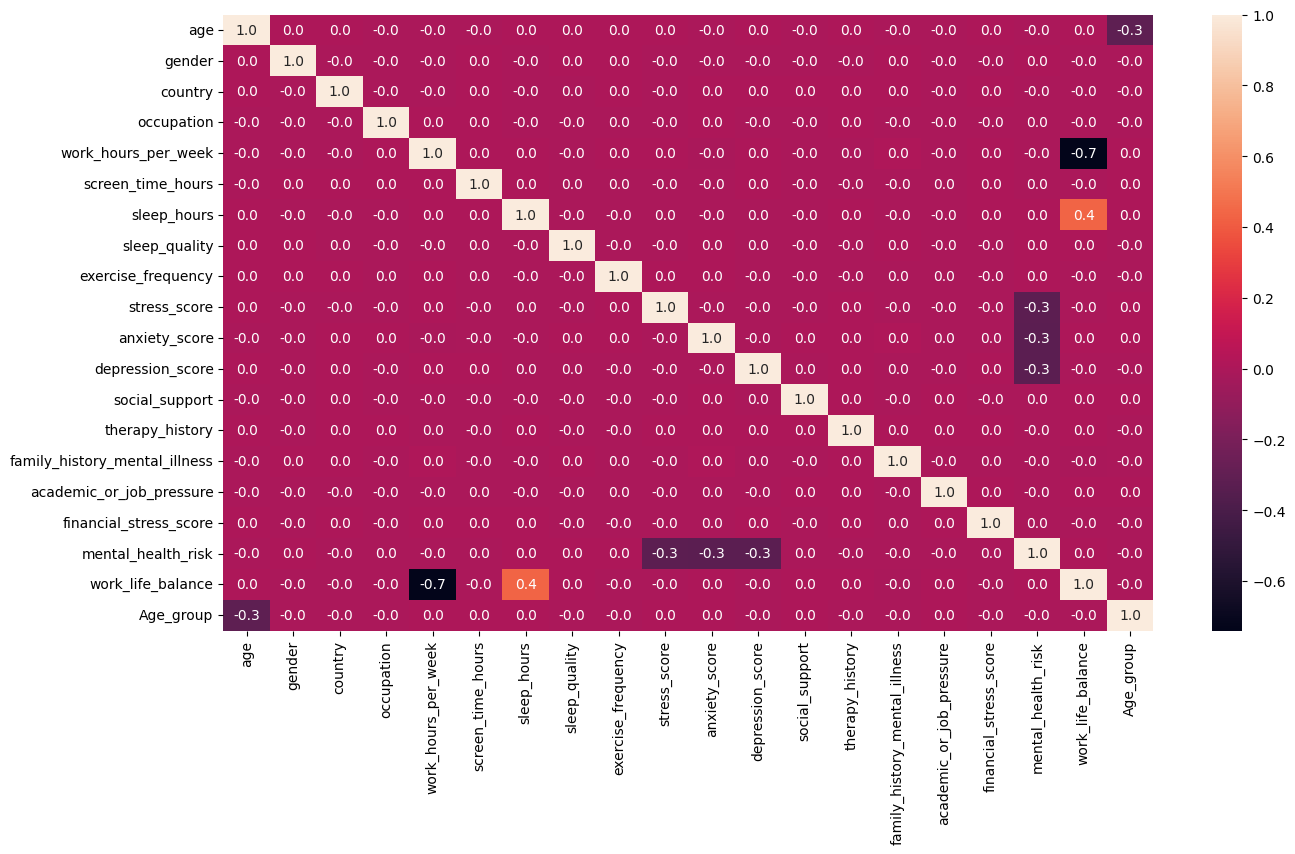

In [66]:
plt.figure(figsize=(15,8))
sns.heatmap(df.corr(),annot=True,fmt="0.1f")
plt.show()